# Museum Artwork Guide — Final Project (m1–m4)

This notebook builds and evaluates the neural-network parts of the museum guide using the local `data/wikiart_subset` dataset.

**Project checkpoints**
- **m1:** Dense feed-forward baseline in PyTorch.
- **m2:** Training/validation curves and error diagnosis.
- **m3:** ImageNet-pretrained ResNet-18, then fine-tuning; compare with the dense baseline.
- **m4:** Text-to-artwork retrieval using TF–IDF (classical) and sentence embeddings (neural), then compare evidence and practical trade-offs.

## 0. Setup

If an import fails, install the missing package in the same Python environment used by this notebook. The core image models use PyTorch/torchvision; m4's sentence-embedding section optionally uses `sentence-transformers`.

In [85]:
from pathlib import Path
import os, random, json, time, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data/wikiart_subset")
OUTPUT_DIR = Path("outputs_official")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Dataset folder exists:", DATA_DIR.exists(), "|", DATA_DIR.resolve())

Device: cpu
Dataset folder exists: True | /Users/tranngocminhhoang/Documents/Netral Network Project/Project-HSM/data/wikiart_subset


## 1. Inspect the dataset and metadata

In [86]:
assert DATA_DIR.exists(), f"Could not find {DATA_DIR.resolve()}. Run the notebook from your project root."
metadata_path = DATA_DIR / "metadata.csv"
metadata = pd.read_csv(metadata_path) if metadata_path.exists() else pd.DataFrame()

print("Metadata shape:", metadata.shape)
display(metadata.head())
print("\nMetadata columns:", metadata.columns.tolist())

Metadata shape: (1500, 11)


,path,label,label_idx,id,style,genre,artist,shard,row,orig_width,orig_height
0,Baroque/s54_r0037.jpg,Baroque,0,s54_r0037,Baroque,landscape,peter-paul-rubens,54,37,2442,1382
1,Baroque/s54_r0159.jpg,Baroque,0,s54_r0159,Baroque,landscape,Unknown Artist,54,159,1682,1382
2,Baroque/s54_r0182.jpg,Baroque,0,s54_r0182,Baroque,landscape,Unknown Artist,54,182,2234,1382
3,Baroque/s54_r0221.jpg,Baroque,0,s54_r0221,Baroque,landscape,peter-paul-rubens,54,221,1821,1382
4,Baroque/s54_r0236.jpg,Baroque,0,s54_r0236,Baroque,still_life,Unknown Artist,54,236,2008,1382



Metadata columns: ['path', 'label', 'label_idx', 'id', 'style', 'genre', 'artist', 'shard', 'row', 'orig_width', 'orig_height']


Number of images: 1500
Classes: ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']
Images per class:


,count
Baroque,300
Cubism,300
Impressionism,300
Pop_Art,300
Ukiyo_e,300


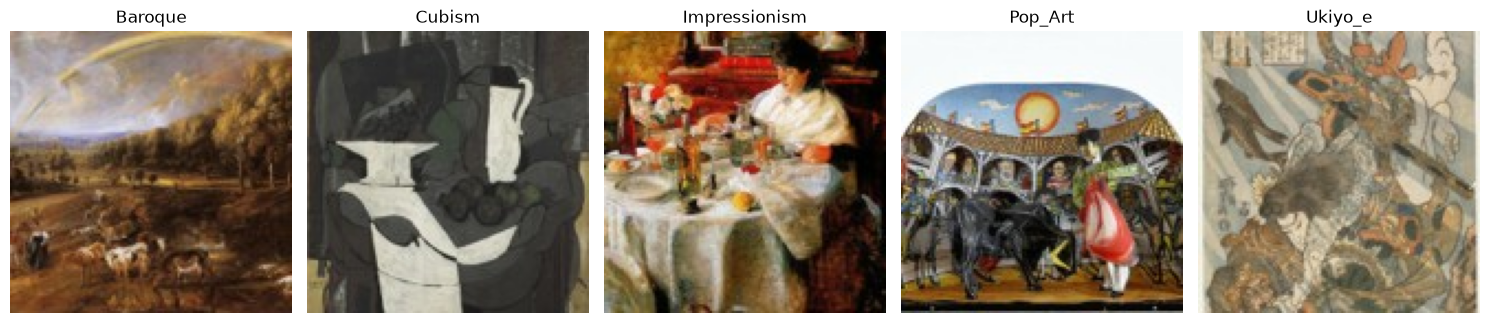

In [87]:
# ImageFolder treats each immediate subfolder as a class label.
# It ignores metadata files at the dataset root.
image_dataset = datasets.ImageFolder(DATA_DIR)
class_names = image_dataset.classes
targets = np.array(image_dataset.targets)
paths = [p for p, _ in image_dataset.samples]

print("Number of images:", len(image_dataset))
print("Classes:", class_names)
print("Images per class:")
display(pd.Series([class_names[y] for y in targets]).value_counts().reindex(class_names).rename("count").to_frame())

# Show a few sample images.
fig, axes = plt.subplots(1, min(5, len(image_dataset)), figsize=(15, 4))
axes = np.atleast_1d(axes)
for ax, idx in zip(axes, np.linspace(0, len(image_dataset)-1, min(5, len(image_dataset)), dtype=int)):
    img, label = image_dataset[idx]
    ax.imshow(img)
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dataset_examples.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Train/validation/test split

We use a stratified split so each style is represented in each split. If any class has too few examples for stratification, adjust the split or collect more images rather than silently trusting the results.

In [ ]:
# Split the dataset into train, validation, and test sets (70/15/15) while preserving class distribution.

indices = np.arange(len(image_dataset))
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=targets
) # 70% train, 30% temp (val+test)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=targets[temp_idx]
) # 15% val, 15% test
print(f"Train: {len(train_idx)} | Validation: {len(val_idx)} | Test: {len(test_idx)}")

# Check the class distribution in each split.
def split_counts(idx, split_name):
    counts = pd.Series(targets[idx]).value_counts().reindex(range(len(class_names)), fill_value=0)
    return pd.DataFrame({"split": split_name, "class": class_names, "count": counts.values})

# Display the class distribution for each split.
display(pd.concat([
    split_counts(train_idx, "train"),
    split_counts(val_idx, "validation"),
    split_counts(test_idx, "test")
], ignore_index=True).pivot(index="class", columns="split", values="count"))

Train: 1050 | Validation: 225 | Test: 225


split,test,train,validation
class,,,
Baroque,45,210,45
Cubism,45,210,45
Impressionism,45,210,45
Pop_Art,45,210,45
Ukiyo_e,45,210,45


## 3. Shared utilities: metrics, training loop, and checkpointing

This is an explicit PyTorch training loop: forward pass → loss → backward pass → optimizer step. Validation runs without gradient tracking. The best model is selected by validation loss and saved under `outputs/`.

In [ ]:
def count_parameters(model, trainable_only=False): # this function counts the number of parameters in a model
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))



def run_epoch(model, loader, loss_fn, optimizer=None): # this function runs one epoch of training or evaluation
    training = optimizer is not None # if optimizer is provided, we are training; otherwise, we are evaluating
    model.train(training) # set the model to training or evaluation mode
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = loss_fn(logits, y)
            if training:
                loss.backward()
                optimizer.step()

        batch_size = y.size(0)
        total_loss += loss.item() * batch_size
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += batch_size
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(y.detach().cpu().numpy())

    return {
        "loss": total_loss / max(total, 1),
        "accuracy": correct / max(total, 1),
        "preds": np.array(all_preds),
        "labels": np.array(all_labels)
    }

# this function trains the model and saves the best model based on validation loss
def fit_model(model, train_loader, val_loader, optimizer, epochs, model_path, scheduler=None): 
    loss_fn = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    patience, patience_limit = 0, 5

    for epoch in range(1, epochs + 1): # loop over the number of epochs
        train_metrics = run_epoch(model, train_loader, loss_fn, optimizer)
        with torch.no_grad():
            val_metrics = run_epoch(model, val_loader, loss_fn, optimizer=None)

        history["train_loss"].append(train_metrics["loss"])
        history["val_loss"].append(val_metrics["loss"])
        history["train_acc"].append(train_metrics["accuracy"])
        history["val_acc"].append(val_metrics["accuracy"])

        if scheduler is not None: # if a learning rate scheduler is provided, step it based on validation loss
            scheduler.step(val_metrics["loss"])

        if val_metrics["loss"] < best_val_loss: # if the validation loss improved, save the model state and reset patience
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, model_path)
            patience = 0
        else:
            patience += 1

        print(f"Epoch {epoch:02d}/{epochs} | " # print the metrics for this epoch
              f"train loss {train_metrics['loss']:.4f}, acc {train_metrics['accuracy']:.3f} | "
              f"val loss {val_metrics['loss']:.4f}, acc {val_metrics['accuracy']:.3f}")

        if patience >= patience_limit: # if the validation loss did not improve for a number of epochs equal to patience_limit, stop training early
            print(f"Early stopping: validation loss did not improve for {patience_limit} epochs.")
            break

    model.load_state_dict(best_state)
    return model, history

def plot_history(history, title, filename): # this function plots the training and validation loss and accuracy over epochs
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="train")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True, alpha=.3)
    axes[1].plot(epochs, history["train_acc"], marker="o", label="train")
    axes[1].plot(epochs, history["val_acc"], marker="o", label="validation")
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True, alpha=.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

def evaluate_classifier(model, loader, name): # this function evaluates the model on a given data loader and prints the accuracy, classification report, and confusion matrix
    model.eval()
    preds, labels = [], []
    with torch.no_grad(): # disable gradient computation for evaluation
        for x, y in loader:
            logits = model(x.to(DEVICE))
            preds.extend(logits.argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    acc = accuracy_score(labels, preds)
    print(f"{name} test accuracy: {acc:.4f}")
    print(classification_report(labels, preds, labels=list(range(len(class_names))),
                                target_names=class_names, zero_division=0))
    cm = confusion_matrix(labels, preds, labels=list(range(len(class_names))))
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(8, 7))
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False, cmap=plt.cm.Blues)
    ax.set_title(f"{name}: test confusion matrix")
    plt.tight_layout()
    safe_name = name.lower().replace(" ", "_")
    plt.savefig(OUTPUT_DIR / f"{safe_name}_confusion_matrix.png", dpi=160, bbox_inches="tight")
    plt.show()
    return acc, np.array(labels), np.array(preds)

## 4. m1 + m2 — Dense feed-forward baseline

A dense model does not explicitly preserve image structure: we resize each image to a small square, flatten the pixels, and feed them into fully connected layers. This gives us a baseline to compare against ResNet. Small images keep the input dimension manageable.

**Important:** this model can be slow or weak on images because flattening loses spatial locality. That is a useful limitation to discuss, not something to hide.

In [ ]:
DENSE_SIZE = 64 # the size to which images will be resized for the dense model
BATCH_SIZE = 32 # the batch size for training and evaluation
NUM_WORKERS = 0 # safe default for notebooks and VS Code on macOS/Windows

dense_transform = transforms.Compose([
    transforms.Resize((DENSE_SIZE, DENSE_SIZE)),
    transforms.ToTensor()
]) # this transform resizes images to DENSE_SIZE x DENSE_SIZE and converts them to tensors

class TransformSubset(Dataset): # this class creates a subset of a dataset with a specific transform applied to the images
    def __init__(self, base_dataset, indices, transform): # initialize the TransformSubset with a base dataset, indices of the subset, and a transform to apply to the images
        self.base_dataset = base_dataset
        self.indices = list(map(int, indices))
        self.transform = transform
    def __len__(self): # return the number of samples in the subset
        return len(self.indices)
    def __getitem__(self, i): # return the transformed image and its label for the i-th index in the subset
        path, label = self.base_dataset.samples[self.indices[i]]
        with Image.open(path) as im:
            im = im.convert("RGB")
            x = self.transform(im)
        return x, int(label)

dense_train_ds = TransformSubset(image_dataset, train_idx, dense_transform)
dense_val_ds = TransformSubset(image_dataset, val_idx, dense_transform)
dense_test_ds = TransformSubset(image_dataset, test_idx, dense_transform)

train_loader = DataLoader(dense_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(dense_val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(dense_test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

class DenseArtworkNet(nn.Module): # this class defines a simple feedforward neural network for image classification
    def __init__(self, num_classes, input_size=DENSE_SIZE): # initialize the DenseArtworkNet with the number of output classes and the input image size
        super().__init__()
        n_in = 3 * input_size * input_size
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_in, 512),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(128, num_classes)
        )
    def forward(self, x): # define the forward pass of the network, which takes an input tensor x and returns the output logits
        return self.net(x)

dense_model = DenseArtworkNet(len(class_names)).to(DEVICE)
print(dense_model)
print("Total parameters:", f"{count_parameters(dense_model):,}")

DenseArtworkNet(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=5, bias=True)
  )
)
Total parameters: 6,358,277


Epoch 01/20 | train loss 2.1454, acc 0.200 | val loss 1.6125, acc 0.240
Epoch 02/20 | train loss 1.6210, acc 0.198 | val loss 1.5917, acc 0.200
Epoch 03/20 | train loss 1.6044, acc 0.218 | val loss 1.5856, acc 0.236
Epoch 04/20 | train loss 1.5934, acc 0.235 | val loss 1.5799, acc 0.280
Epoch 05/20 | train loss 1.5587, acc 0.271 | val loss 1.5642, acc 0.280
Epoch 06/20 | train loss 1.5332, acc 0.300 | val loss 1.5437, acc 0.298
Epoch 07/20 | train loss 1.5277, acc 0.282 | val loss 1.5419, acc 0.298
Epoch 08/20 | train loss 1.5101, acc 0.305 | val loss 1.5379, acc 0.311
Epoch 09/20 | train loss 1.5138, acc 0.310 | val loss 1.5366, acc 0.324
Epoch 10/20 | train loss 1.4992, acc 0.329 | val loss 1.5372, acc 0.329
Epoch 11/20 | train loss 1.5004, acc 0.318 | val loss 1.5287, acc 0.342
Epoch 12/20 | train loss 1.4948, acc 0.313 | val loss 1.5316, acc 0.302
Epoch 13/20 | train loss 1.4811, acc 0.320 | val loss 1.5461, acc 0.276
Epoch 14/20 | train loss 1.4864, acc 0.314 | val loss 1.5461, ac

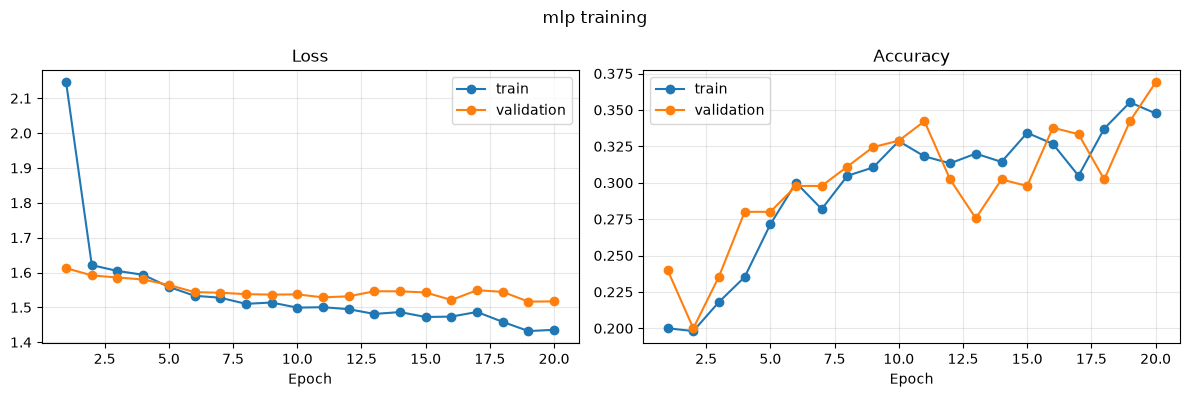

In [ ]:
# this optimizer uses the Adam algorithm with a learning rate of 0.001 and weight decay of 0.0001 for regularization
dense_optimizer = torch.optim.Adam(dense_model.parameters(), lr=1e-3, weight_decay=1e-4) 

# this trains the dense model using the training and validation data loaders, optimizer, and specified number of epochs, saving the best model based on validation loss
dense_model, dense_history = fit_model(
    dense_model, train_loader, val_loader, dense_optimizer,
    epochs=20, model_path=OUTPUT_DIR / "mlp_best.pt"
)

# this plots the training and validation loss and accuracy over epochs for the dense model
plot_history(dense_history, "mlp training", "mlp_training_curves.png")

### m2 diagnosis: interpret the curves

- **Underfitting:** training and validation accuracy are both low; both losses remain high.
- **Overfitting:** training loss keeps falling / training accuracy rises, while validation loss rises or validation accuracy stalls.
- **Potential data/split issue:** suspiciously high validation accuracy can mean near-duplicate images, leakage, or a very small/easy validation set.
- **Class confusion:** use the confusion matrix and misclassified examples below to identify the most difficult styles.

The training results show that the MLP model is learning, as both training and validation loss generally decrease while accuracy improves over the 20 epochs. Training accuracy reaches 34.8%, and validation accuracy reaches 36.9%, indicating gradual improvement in classification performance. However, validation loss and accuracy fluctuate across epochs, suggesting some instability during training. There is no clear evidence of severe overfitting, since validation performance does not consistently deteriorate as training progresses. Nevertheless, the relatively low accuracy suggests possible underfitting or limitations in the model configuration. To improve performance, further hyperparameter tuning, learning-rate adjustment, data preprocessing checks, and experiments with model architecture are recommended.

mlp test accuracy: 0.3867
               precision    recall  f1-score   support

      Baroque       0.52      0.53      0.53        45
       Cubism       0.67      0.04      0.08        45
Impressionism       0.27      0.07      0.11        45
      Pop_Art       0.46      0.38      0.41        45
      Ukiyo_e       0.32      0.91      0.47        45

     accuracy                           0.39       225
    macro avg       0.45      0.39      0.32       225
 weighted avg       0.45      0.39      0.32       225



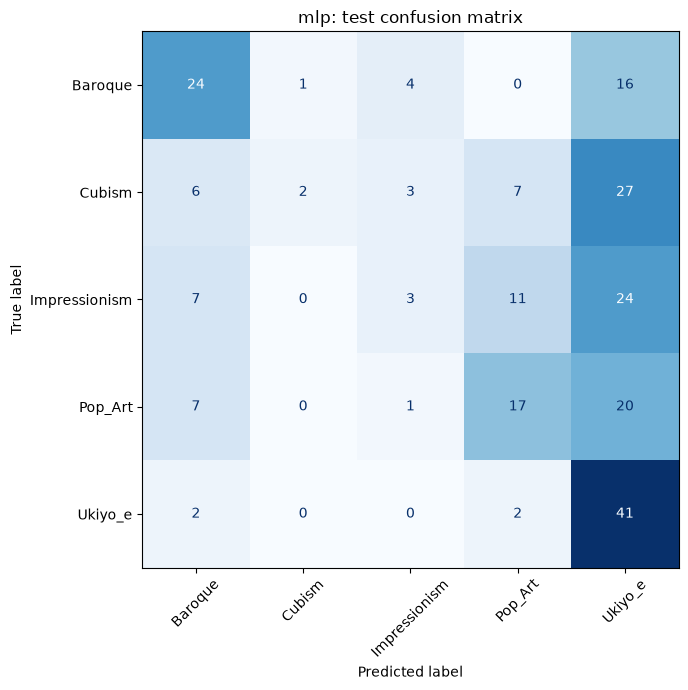

In [ ]:
# this evaluates the trained dense model on the test set and prints the accuracy, classification report, and confusion matrix
dense_test_acc, y_true_dense, y_pred_dense = evaluate_classifier(dense_model, test_loader, "mlp")

Showing 12 misclassified test images (first 12 found).


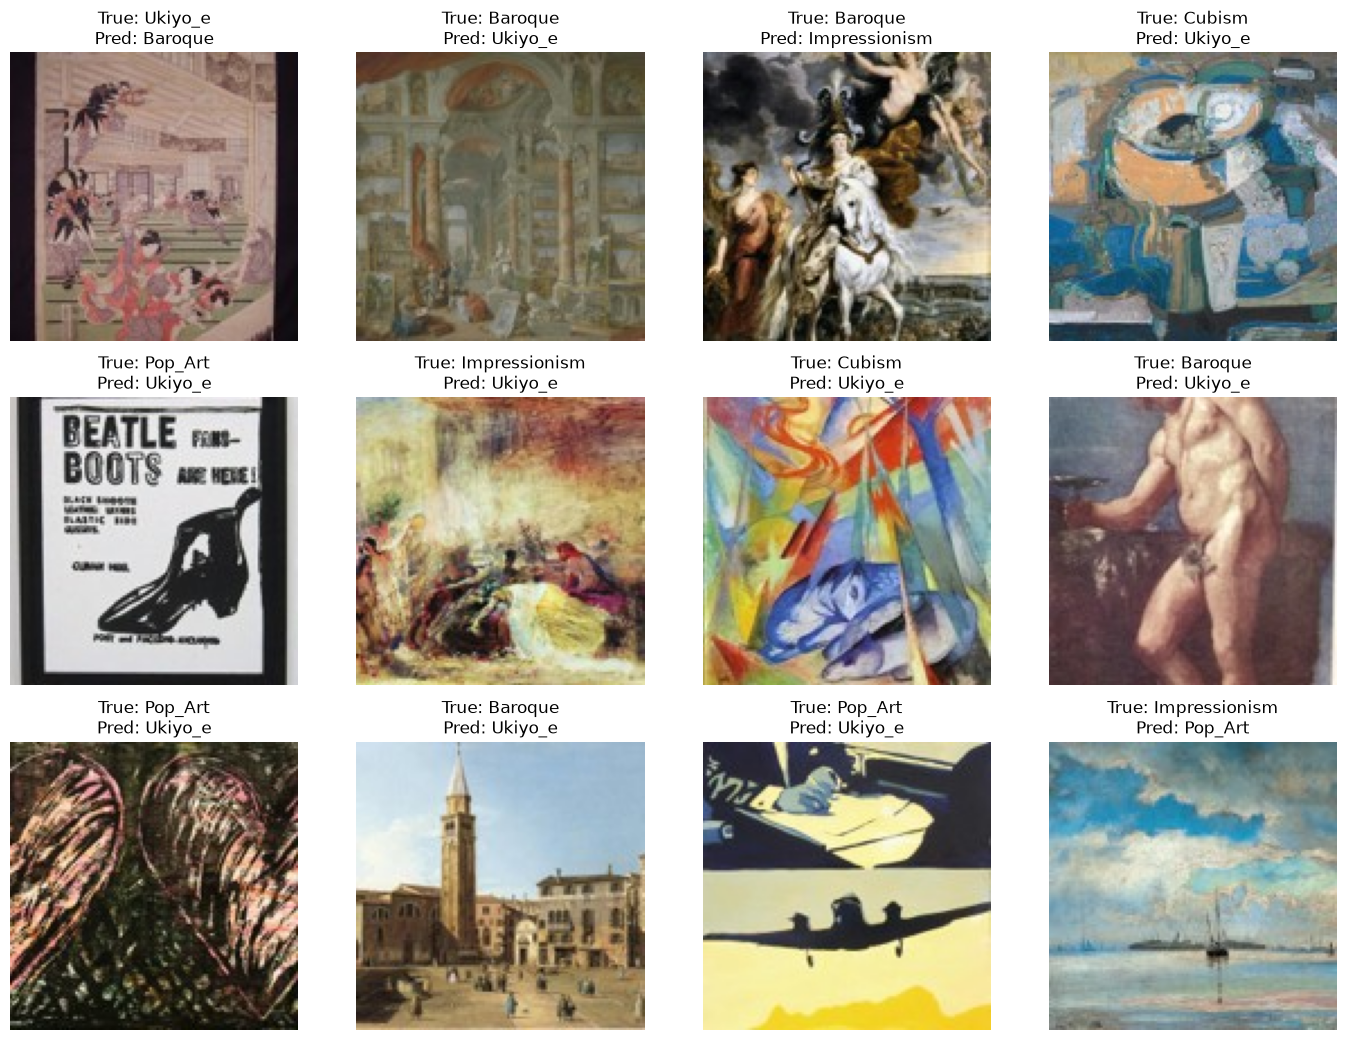

In [ ]:
# Display and save a selection of test mistakes for qualitative diagnosis.
dense_model.eval()
mistakes = []
with torch.no_grad():
    for i in test_idx:
        path, true_label = image_dataset.samples[int(i)]
        with Image.open(path) as im:
            x = dense_transform(im.convert("RGB")).unsqueeze(0).to(DEVICE)
        pred_label = int(dense_model(x).argmax(1).item())
        if pred_label != true_label:
            mistakes.append((path, true_label, pred_label))
        if len(mistakes) >= 12:
            break

print(f"Showing {len(mistakes)} misclassified test images (first 12 found).")
if mistakes:
    fig, axes = plt.subplots((len(mistakes)+3)//4, 4, figsize=(14, 3.5*((len(mistakes)+3)//4)))
    axes = np.array(axes).reshape(-1)
    for ax, (path, true_label, pred_label) in zip(axes, mistakes):
        ax.imshow(Image.open(path).convert("RGB"))
        ax.set_title(f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}")
        ax.axis("off")
    for ax in axes[len(mistakes):]: ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "dense_misclassified_examples.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("No mistakes found in the inspected subset.")

## 5. m3 — Transfer learning and fine-tuning ResNet-18

Following Session 7: load ImageNet-pretrained ResNet-18, replace the 1000-class output layer with a layer for our artwork styles, freeze the backbone and train the new head. Then unfreeze `layer4` and fine-tune it with a smaller learning rate than the new head.

Images are resized and normalized with ImageNet's channel statistics, as in the course slides. If pretrained weights cannot be downloaded, check internet access and the local torchvision installation.

In [98]:
RESNET_SIZE = 224
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)
resnet_transform = transforms.Compose([
    transforms.Resize((RESNET_SIZE, RESNET_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

resnet_train_ds = TransformSubset(image_dataset, train_idx, resnet_transform)
resnet_val_ds = TransformSubset(image_dataset, val_idx, resnet_transform)
resnet_test_ds = TransformSubset(image_dataset, test_idx, resnet_transform)
resnet_train_loader = DataLoader(resnet_train_ds, batch_size=16, shuffle=True, num_workers=NUM_WORKERS)
resnet_val_loader = DataLoader(resnet_val_ds, batch_size=16, shuffle=False, num_workers=NUM_WORKERS)
resnet_test_loader = DataLoader(resnet_test_ds, batch_size=16, shuffle=False, num_workers=NUM_WORKERS)

from torchvision.models import resnet18, ResNet18_Weights
resnet_model = resnet18(weights=ResNet18_Weights.DEFAULT)
for p in resnet_model.parameters():
    p.requires_grad = False
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, len(class_names))
resnet_model = resnet_model.to(DEVICE)

print("All parameters:", f"{count_parameters(resnet_model):,}")
print("Trainable parameters with frozen backbone:", f"{count_parameters(resnet_model, trainable_only=True):,}")

All parameters: 11,179,077
Trainable parameters with frozen backbone: 2,565


Epoch 01/8 | train loss 1.3379, acc 0.458 | val loss 1.0268, acc 0.618
Epoch 02/8 | train loss 0.9273, acc 0.686 | val loss 0.8566, acc 0.667
Epoch 03/8 | train loss 0.8226, acc 0.697 | val loss 0.7839, acc 0.698
Epoch 04/8 | train loss 0.7302, acc 0.737 | val loss 0.7544, acc 0.689
Epoch 05/8 | train loss 0.6813, acc 0.757 | val loss 0.7213, acc 0.729
Epoch 06/8 | train loss 0.6495, acc 0.766 | val loss 0.6729, acc 0.738
Epoch 07/8 | train loss 0.6187, acc 0.790 | val loss 0.6962, acc 0.716
Epoch 08/8 | train loss 0.5865, acc 0.805 | val loss 0.6392, acc 0.747


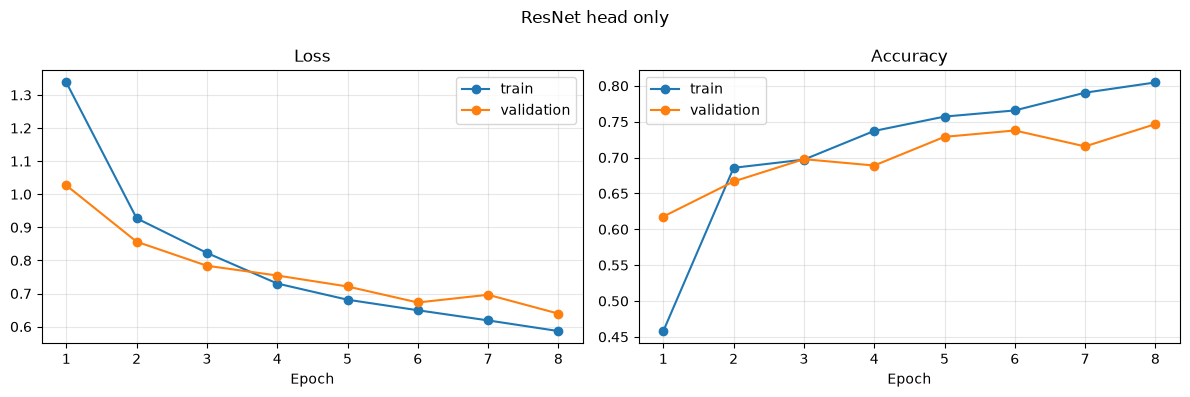

Best recorded head-only validation accuracy: 0.7467


In [99]:
# Stage 1: train only the new classification head.
head_optimizer = torch.optim.Adam(resnet_model.fc.parameters(), lr=1e-3)
resnet_model, head_history = fit_model(
    resnet_model, resnet_train_loader, resnet_val_loader, head_optimizer,
    epochs=8, model_path=OUTPUT_DIR / "resnet_head_best.pt"
)
plot_history(head_history, "ResNet head only", "resnet_head_training_curves.png")
head_val_acc = head_history["val_acc"][int(np.argmin(head_history["val_loss"]))]
print(f"Best recorded head-only validation accuracy: {head_val_acc:.4f}")

Epoch 01/10 | train loss 0.5981, acc 0.769 | val loss 0.5688, acc 0.769
Epoch 02/10 | train loss 0.1737, acc 0.949 | val loss 0.5677, acc 0.791
Epoch 03/10 | train loss 0.0815, acc 0.978 | val loss 0.5773, acc 0.804
Epoch 04/10 | train loss 0.0518, acc 0.990 | val loss 0.6219, acc 0.787
Epoch 05/10 | train loss 0.0377, acc 0.993 | val loss 0.6670, acc 0.764
Epoch 06/10 | train loss 0.0165, acc 0.998 | val loss 0.6783, acc 0.800
Epoch 07/10 | train loss 0.0160, acc 0.996 | val loss 0.6536, acc 0.787
Early stopping: validation loss did not improve for 5 epochs.


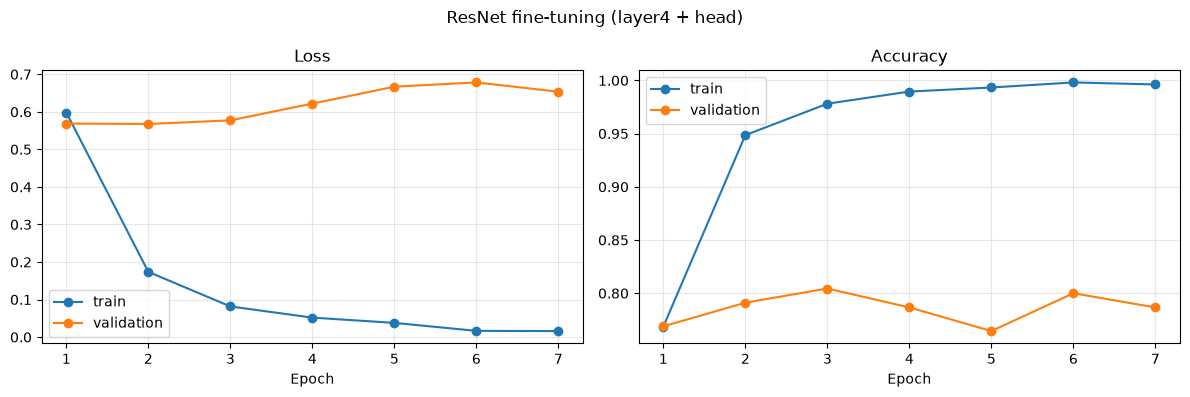

In [100]:
# Stage 2: unfreeze the final residual block (layer4) and fine-tune with a smaller LR.
for p in resnet_model.layer4.parameters():
    p.requires_grad = True

fine_optimizer = torch.optim.Adam([
    {"params": resnet_model.layer4.parameters(), "lr": 1e-4},
    {"params": resnet_model.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-4)

resnet_model, fine_history = fit_model(
    resnet_model, resnet_train_loader, resnet_val_loader, fine_optimizer,
    epochs=10, model_path=OUTPUT_DIR / "resnet_finetuned_best.pt"
)
plot_history(fine_history, "ResNet fine-tuning (layer4 + head)", "resnet_finetuning_curves.png")

ResNet fine-tuned test accuracy: 0.8000
               precision    recall  f1-score   support

      Baroque       0.80      0.87      0.83        45
       Cubism       0.87      0.73      0.80        45
Impressionism       0.80      0.73      0.77        45
      Pop_Art       0.69      0.78      0.73        45
      Ukiyo_e       0.87      0.89      0.88        45

     accuracy                           0.80       225
    macro avg       0.81      0.80      0.80       225
 weighted avg       0.81      0.80      0.80       225



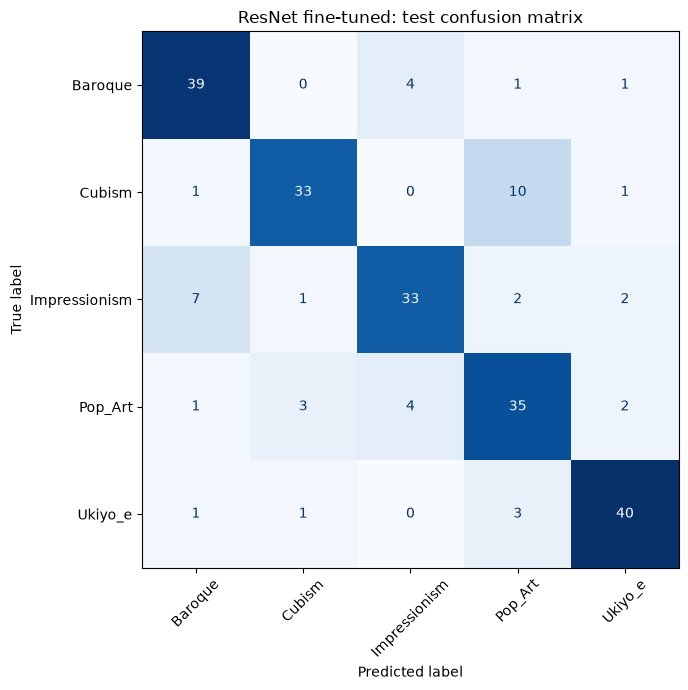

In [101]:
resnet_test_acc, y_true_resnet, y_pred_resnet = evaluate_classifier(
    resnet_model, resnet_test_loader, "ResNet fine-tuned"
)

In [102]:
# Compare held-out test accuracy. A single run is evidence for this split/seed, not proof of universal superiority.
comparison = pd.DataFrame([
    {"model": "Dense baseline", "test_accuracy": dense_test_acc,
     "trainable_parameters": count_parameters(dense_model, trainable_only=True)},
    {"model": "ResNet-18 fine-tuned", "test_accuracy": resnet_test_acc,
     "trainable_parameters_during_finetuning": sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)}
])
display(comparison)
comparison.to_csv(OUTPUT_DIR / "image_model_comparison.csv", index=False)

,model,test_accuracy,trainable_parameters,trainable_parameters_during_finetuning
0,Dense baseline,0.386667,6358277.0,NaN
1,ResNet-18 fine-tuned,0.800000,NaN,8396293.0


## 6. m4 — Question-to-artwork retrieval (classical TF–IDF vs sentence embeddings)

Image folders alone provide **style labels**, not reliable descriptions such as “stormy sea” or “portraits of children”. The retrieval task needs textual metadata (title, description, genre, tags, etc.). This section inspects `metadata.csv` and tries to match rows to image filenames. Check the printed columns and sample rows; adjust `TEXT_COLUMNS` and `IMAGE_COLUMN` if the metadata uses different names.

If the CSV has no descriptions/titles, the notebook will explain that retrieval cannot be meaningfully evaluated until textual artwork metadata is supplied.

In [103]:
print("Metadata columns:", metadata.columns.tolist())
display(metadata.head(10))

# Try to infer likely image-path and text fields. Edit these lists if your CSV uses other names.
image_candidates = ["filename", "file_name", "image", "image_path", "path", "file", "id"]
text_candidates = ["title", "description", "genre", "tags", "caption", "artist", "style", "text"]

def find_column(candidates, columns):
    lower_map = {str(c).lower(): c for c in columns}
    for candidate in candidates:
        if candidate in lower_map:
            return lower_map[candidate]
    return None

IMAGE_COLUMN = find_column(image_candidates, metadata.columns) if not metadata.empty else None
TEXT_COLUMNS = [c for c in metadata.columns if str(c).lower() in text_candidates] if not metadata.empty else []

print("Inferred image column:", IMAGE_COLUMN)
print("Inferred text columns:", TEXT_COLUMNS)

Metadata columns: ['path', 'label', 'label_idx', 'id', 'style', 'genre', 'artist', 'shard', 'row', 'orig_width', 'orig_height']


,path,label,label_idx,id,style,genre,artist,shard,row,orig_width,orig_height
0,Baroque/s54_r0037.jpg,Baroque,0,s54_r0037,Baroque,landscape,peter-paul-rubens,54,37,2442,1382
1,Baroque/s54_r0159.jpg,Baroque,0,s54_r0159,Baroque,landscape,Unknown Artist,54,159,1682,1382
2,Baroque/s54_r0182.jpg,Baroque,0,s54_r0182,Baroque,landscape,Unknown Artist,54,182,2234,1382
3,Baroque/s54_r0221.jpg,Baroque,0,s54_r0221,Baroque,landscape,peter-paul-rubens,54,221,1821,1382
4,Baroque/s54_r0236.jpg,Baroque,0,s54_r0236,Baroque,still_life,Unknown Artist,54,236,2008,1382
5,Baroque/s54_r0282.jpg,Baroque,0,s54_r0282,Baroque,still_life,Unknown Artist,54,282,1957,1382
6,Baroque/s54_r0285.jpg,Baroque,0,s54_r0285,Baroque,still_life,Unknown Artist,54,285,1989,1382
7,Baroque/s54_r0296.jpg,Baroque,0,s54_r0296,Baroque,still_life,Unknown Artist,54,296,2050,1382
8,Baroque/s54_r0298.jpg,Baroque,0,s54_r0298,Baroque,still_life,Unknown Artist,54,298,1382,1587
9,Baroque/s54_r0311.jpg,Baroque,0,s54_r0311,Baroque,still_life,frans-hals,54,311,1382,1812


Inferred image column: path
Inferred text columns: ['style', 'genre', 'artist']


In [104]:
# Build one text record per image path, using metadata when possible and folder labels as fallback.
# If the metadata's filename column contains only basenames, basename matching should work.
image_records = pd.DataFrame({
    "path": paths,
    "label_id": targets,
    "style": [class_names[y] for y in targets],
    "basename": [Path(p).name for p in paths],
    "relative_path": [str(Path(p).relative_to(DATA_DIR)) for p in paths]
})
image_records["text"] = image_records["style"]

if not metadata.empty and IMAGE_COLUMN is not None and TEXT_COLUMNS:
    meta = metadata.copy()
    meta["_basename"] = meta[IMAGE_COLUMN].astype(str).map(lambda x: Path(x).name)
    meta["_text"] = meta[TEXT_COLUMNS].fillna("").astype(str).agg(" ".join, axis=1).str.strip()
    meta = meta.drop_duplicates("_basename").set_index("_basename")
    matched = image_records["basename"].isin(meta.index)
    image_records.loc[matched, "text"] = image_records.loc[matched, "basename"].map(meta["_text"])
    print(f"Metadata text matched for {matched.sum()}/{len(image_records)} images.")
else:
    print("Using style names only. This is not enough to answer content questions such as 'stormy sea'.")

display(image_records[["basename", "style", "text"]].head())
image_records.to_csv(OUTPUT_DIR / "artwork_text_index.csv", index=False)

Metadata text matched for 1500/1500 images.


,basename,style,text
0,s54_r0037.jpg,Baroque,Baroque landscape peter-paul-rubens
1,s54_r0159.jpg,Baroque,Baroque landscape Unknown Artist
2,s54_r0182.jpg,Baroque,Baroque landscape Unknown Artist
3,s54_r0221.jpg,Baroque,Baroque landscape peter-paul-rubens
4,s54_r0236.jpg,Baroque,Baroque still_life Unknown Artist


In [105]:
# Optional neural retrieval using pretrained sentence embeddings.
# Install if needed: %pip install sentence-transformers
try:
    from sentence_transformers import SentenceTransformer
    sentence_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    sentence_embeddings = sentence_model.encode(
        retrieval_texts, convert_to_numpy=True, normalize_embeddings=True,
        show_progress_bar=True
    )

    def search_embeddings(query, top_k=5):
        q_emb = sentence_model.encode([query], convert_to_numpy=True, normalize_embeddings=True)
        scores = sentence_embeddings @ q_emb[0]
        best = np.argsort(scores)[::-1][:top_k]
        result = image_records.iloc[best][["basename", "style", "text", "path"]].copy()
        result["similarity"] = scores[best]
        return result

    for query in example_queries:
        print("\nSENTENCE-EMBEDDING QUERY:", query)
        display(search_embeddings(query, top_k=5))
    print("Sentence embeddings ready.")
except Exception as e:
    sentence_model = None
    sentence_embeddings = None
    print("Sentence embedding section could not run:", repr(e))
    print("TF–IDF remains available. If the error is a missing package, run: %pip install sentence-transformers")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8859.99it/s]


Sentence embedding section could not run: NameError("name 'retrieval_texts' is not defined")
TF–IDF remains available. If the error is a missing package, run: %pip install sentence-transformers


### Save an experiment summary


In [106]:
summary = {
    "dataset": str(DATA_DIR),
    "classes": class_names,
    "n_images": len(image_dataset),
    "n_train": len(train_idx),
    "n_validation": len(val_idx),
    "n_test": len(test_idx),
    "dense_test_accuracy": float(dense_test_acc),
    "resnet_finetuned_test_accuracy": float(resnet_test_acc),
    "device": str(DEVICE),
    "seed": SEED
}
with open(OUTPUT_DIR / "experiment_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("\nSaved artifacts:")
for p in sorted(OUTPUT_DIR.glob("*")):
    print("-", p)

{
  "dataset": "data/wikiart_subset",
  "classes": [
    "Baroque",
    "Cubism",
    "Impressionism",
    "Pop_Art",
    "Ukiyo_e"
  ],
  "n_images": 1500,
  "n_train": 1050,
  "n_validation": 225,
  "n_test": 225,
  "dense_test_accuracy": 0.38666666666666666,
  "resnet_finetuned_test_accuracy": 0.8,
  "device": "cpu",
  "seed": 42
}

Saved artifacts:
- outputs_official/artwork_text_index.csv
- outputs_official/dataset_examples.png
- outputs_official/dense_misclassified_examples.png
- outputs_official/experiment_summary.json
- outputs_official/image_model_comparison.csv
- outputs_official/mlp_best.pt
- outputs_official/mlp_confusion_matrix.png
- outputs_official/mlp_training_curves.png
- outputs_official/resnet_fine-tuned_confusion_matrix.png
- outputs_official/resnet_finetuned_best.pt
- outputs_official/resnet_finetuning_curves.png
- outputs_official/resnet_head_best.pt
- outputs_official/resnet_head_training_curves.png
